Running: 0
Running: A
Running: B
Running: AB


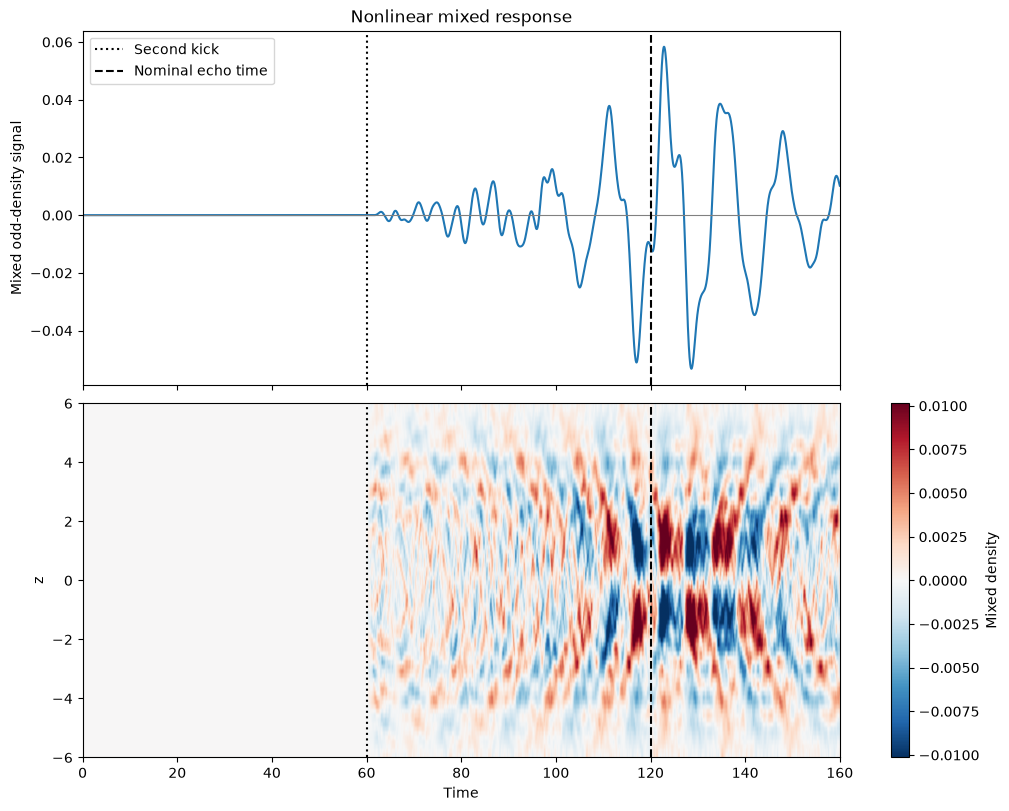

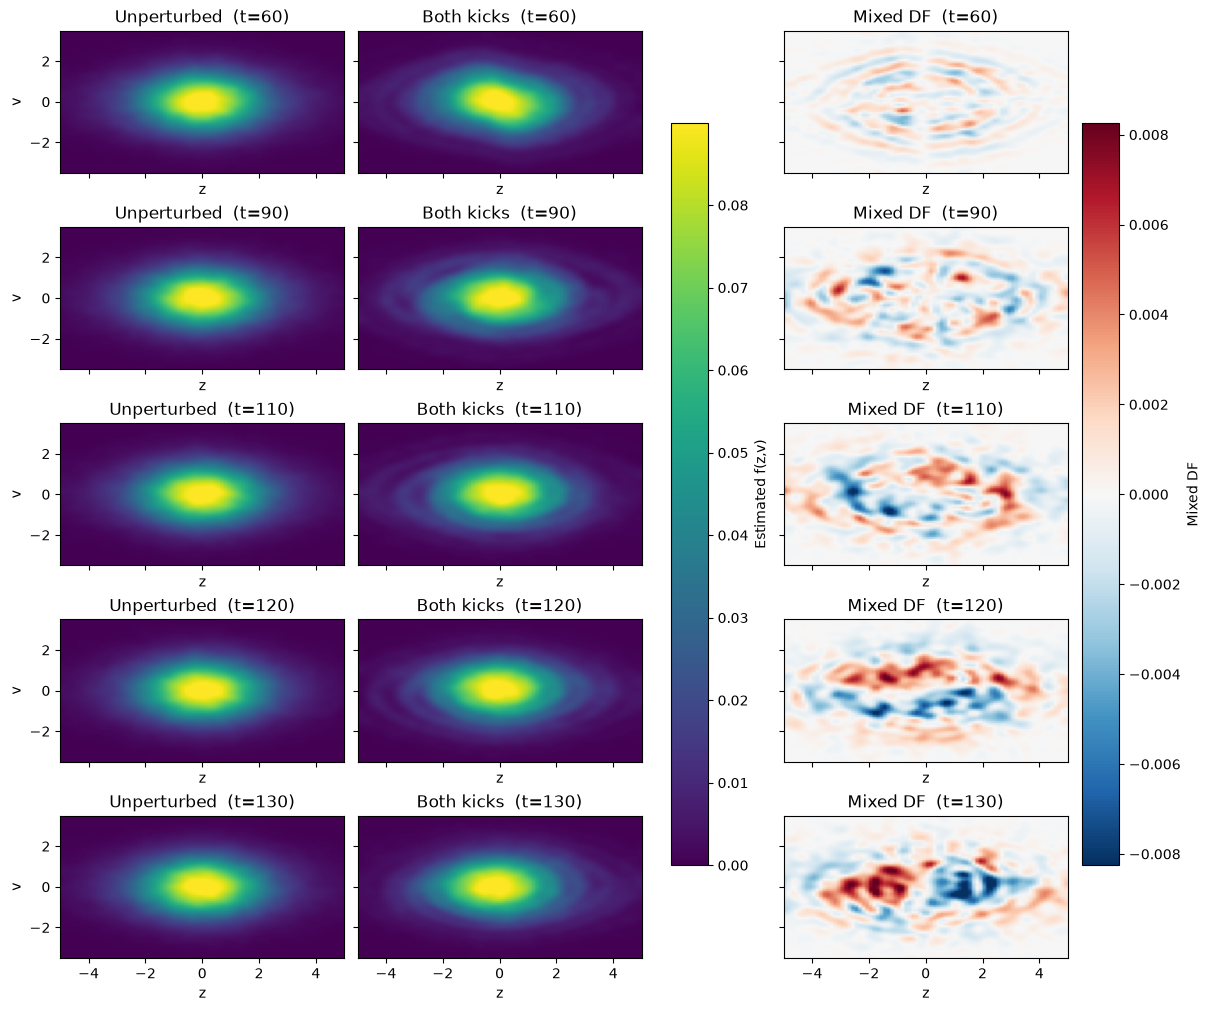

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import wendy
from scipy.ndimage import gaussian_filter1d

# --- Parameters ---
N = 100000
H = sigma = 1.0
dt = 0.05
nleap = 2

t2 = 60.0
tmax = 160.0

A1, L = 0.40, 1.2     # First kick
A2, a = 0.20, 1.0     # Plummer kick

# --- Same equilibrium for every simulation ---
rng = np.random.default_rng(42)

z0 = 2 * H * np.arctanh(2 * rng.random(N) - 1)
v0 = rng.normal(0, sigma, N)

z0 -= z0.mean()
v0 -= v0.mean()
m = np.ones(N) / N

# --- Impulses ---
def kick_A(z):
    return -A1 * np.cos(z / L)

def kick_B(z):
    return -A2 * 2 * a * z / (z**2 + a**2)

# --- Recording parameters ---
nt = round(tmax / dt)
k2 = round(t2 / dt)
times = np.arange(nt + 1) * dt

edges = np.linspace(-6, 6, 81)
dz = edges[1] - edges[0]

snapshot_times = snapshot_times = [60.0, 90.0, 110.0, 120.0, 130.0]
snapshot_steps = {round(t / dt) for t in snapshot_times}
snapshot_steps = {round(t / dt) for t in snapshot_times}

def simulate(use_A=False, use_B=False):
    z, v = z0.copy(), v0.copy()

    if use_A:
        dv = kick_A(z)
        v += dv - dv.mean()

    g = wendy.nbody(z, v, m, dt, approx=True, nleap=nleap)

    density = np.zeros((nt + 1, len(edges) - 1))
    signal = np.zeros(nt + 1)
    snapshots = {}

    for i in range(nt + 1):

        # Apply second impulse exactly at t2
        if i == k2 and use_B:
            dv = kick_B(z)
            v = v + dv - dv.mean()
            g = wendy.nbody(z, v, m, dt,
                            approx=True, nleap=nleap)

        # Work relative to the instantaneous centre of mass
        zc = z - z.mean()
        if i in snapshot_steps:
            snapshots[i] = (zc.copy(), (v - v.mean()).copy())
        density[i] = np.histogram(zc, bins=edges)[0] / (N * dz)

        # Bounded odd-density observable
        signal[i] = np.mean(np.sin(zc / H))

        if i < nt:
            z, v = next(g)

    return density, signal, snapshots

# --- Four simulations ---
results = {}

for name, use_A, use_B in [
    ("0",  False, False),
    ("A",  True,  False),
    ("B",  False, True),
    ("AB", True,  True)
]:
    print("Running:", name)
    results[name] = simulate(use_A, use_B)

# --- Isolate the mixed response ---
rho_mix = (results["AB"][0] - results["A"][0]
           - results["B"][0] + results["0"][0])

signal_mix = (results["AB"][1] - results["A"][1]
              - results["B"][1] + results["0"][1])

# Smooth the density spatially for visualization only
rho_plot = gaussian_filter1d(rho_mix, sigma=1.5, axis=1)

# --- Plot ---
fig, axes = plt.subplots(2, 1, figsize=(10, 8),
                         sharex=True, layout="constrained")

axes[0].plot(times, signal_mix)
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Mixed odd-density signal")
axes[0].set_title("Nonlinear mixed response")

lim = max(np.percentile(np.abs(rho_plot), 99), 1e-12)

im = axes[1].imshow(
    rho_plot.T,
    origin="lower",
    aspect="auto",
    extent=[times[0], times[-1], edges[0], edges[-1]],
    cmap="RdBu_r",
    vmin=-lim,
    vmax=lim
)

axes[1].set_ylabel("z")
axes[1].set_xlabel("Time")
fig.colorbar(im, ax=axes[1], label="Mixed density")

for ax in axes:
    ax.axvline(t2, color="black", ls=":",
               label="Second kick")
    ax.axvline(2*t2, color="black", ls="--",
               label="Nominal echo time")

axes[0].legend()
plt.show()



from scipy.ndimage import gaussian_filter

z_edges = np.linspace(-5, 5, 81)
v_edges = np.linspace(-3.5, 3.5, 71)

dz = z_edges[1] - z_edges[0]
dv = v_edges[1] - v_edges[0]

def estimate_df(z, v):
    hist, _, _ = np.histogram2d(
        z, v, bins=[z_edges, v_edges]
    )
    # Coarse-grained DF, normalized to unit total mass
    return gaussian_filter(
        hist / (N * dz * dv), sigma=1.5
    )

# Estimate all four DFs at each snapshot time
snap_data = []

for t in snapshot_times:
    step = round(t / dt)

    dfs = {}
    for name in ["0", "A", "B", "AB"]:
        z, v = results[name][2][step]
        dfs[name] = estimate_df(z, v)

    df_mix = (
        dfs["AB"] - dfs["A"]
        - dfs["B"] + dfs["0"]
    )
    snap_data.append((dfs["0"], dfs["AB"], df_mix))

# Consistent colour scales across times
f_max = max(
    np.percentile(f, 99)
    for f0, fAB, fmix in snap_data
    for f in (f0, fAB)
)
mix_max = max(
    np.percentile(np.abs(fmix), 99)
    for f0, fAB, fmix in snap_data
)
mix_max = max(mix_max, 1e-12)

fig, axes = plt.subplots(
    len(snapshot_times), 3,
    figsize=(12, 10),
    sharex=True, sharey=True,
    layout="constrained"
)

extent = [
    z_edges[0], z_edges[-1],
    v_edges[0], v_edges[-1]
]

for row, t in enumerate(snapshot_times):
    f0, fAB, fmix = snap_data[row]

    for col, data in enumerate([f0, fAB, fmix]):
        mixed = col == 2

        im = axes[row, col].imshow(
            data.T,
            origin="lower",
            extent=extent,
            aspect="auto",
            cmap="RdBu_r" if mixed else "viridis",
            vmin=-mix_max if mixed else 0,
            vmax=mix_max if mixed else f_max
        )

        if mixed:
            im_mix = im
        else:
            im_df = im

        axes[row, col].set_title(
            ["Unperturbed", "Both kicks",
             "Mixed DF"][col] + f"  (t={t:g})"
        )

        axes[row, col].set_xlabel("z")

    axes[row, 0].set_ylabel("v")

fig.colorbar(
    im_df, ax=axes[:, :2],
    label="Estimated f(z,v)", shrink=0.8
)
fig.colorbar(
    im_mix, ax=axes[:, 2],
    label="Mixed DF", shrink=0.8
)

plt.show()


Running equilibrium...
Running single perturbation...


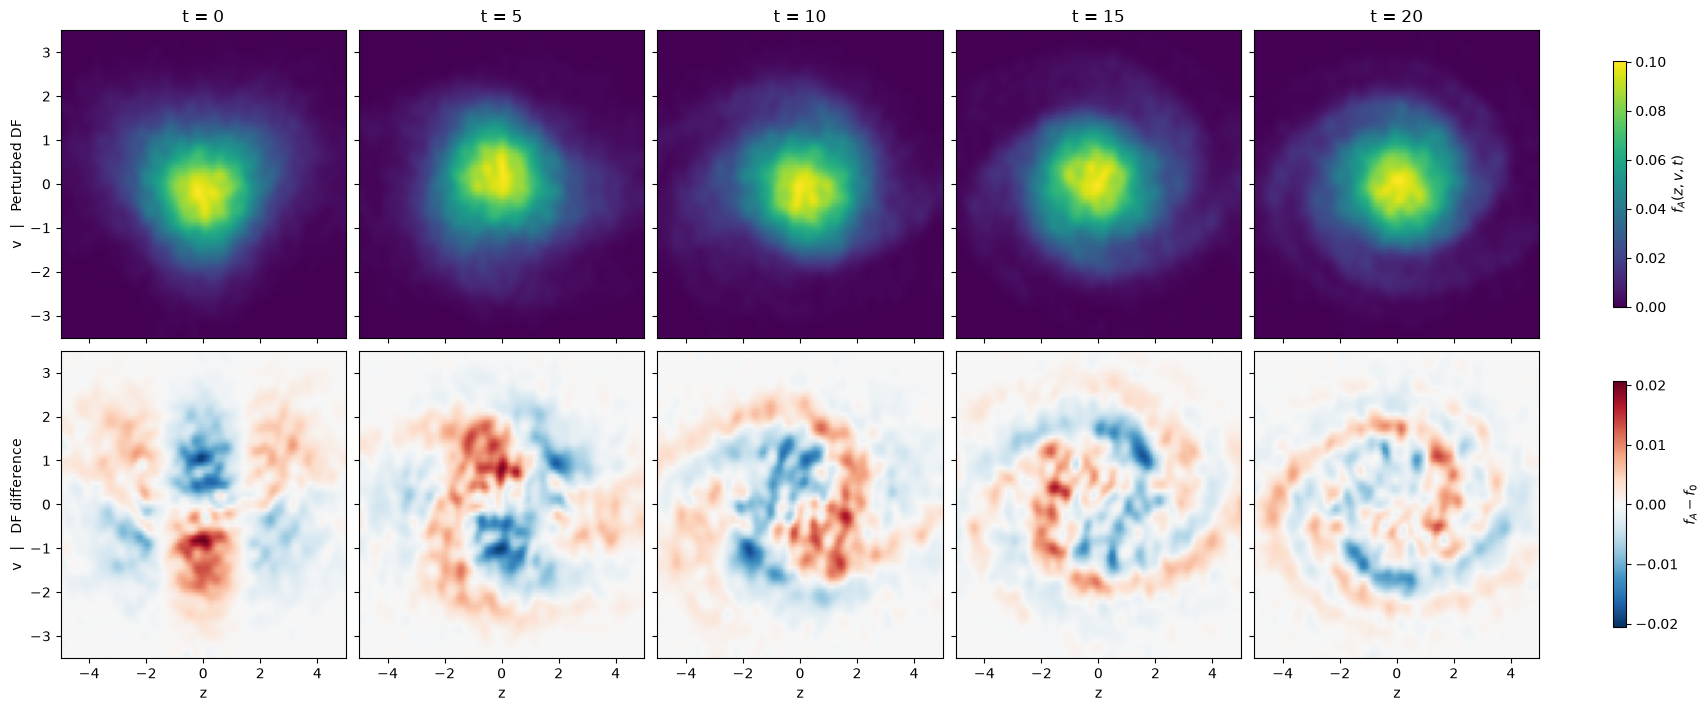

In [7]:

import numpy as np
import matplotlib.pyplot as plt
import wendy
from scipy.ndimage import gaussian_filter

# --- Parameters ---
N = 30000
H = sigma = 1.0
dt, tmax = 0.05, 20.0
nleap = 2

A1, L = 0.4, 1.2
snapshot_times = [0, 5, 10, 15, 20]

# --- Equilibrium initial conditions ---
rng = np.random.default_rng(42)

z0 = 2 * H * np.arctanh(2 * rng.random(N) - 1)
v0 = rng.normal(0, sigma, N)

z0 -= z0.mean()
v0 -= v0.mean()
m = np.ones(N) / N

# --- First impulse ---
def kick_A(z):
    return -A1 * np.cos(z / L)

# Remove centre-of-mass velocity change
dv_A = kick_A(z0)
dv_A -= dv_A.mean()

# --- Evolve unperturbed and perturbed systems ---
steps = {round(t / dt): t for t in snapshot_times}
nt = round(tmax / dt)

def evolve(v_initial):
    z = z0.copy()
    v = v_initial.copy()

    sim = wendy.nbody(
        z, v, m, dt,
        approx=True, nleap=nleap
    )

    snapshots = {}

    for i in range(nt + 1):
        if i in steps:
            snapshots[steps[i]] = (
                (z - z.mean()).copy(),
                (v - v.mean()).copy()
            )

        if i < nt:
            z, v = next(sim)

    return snapshots

print("Running equilibrium...")
snap_0 = evolve(v0)

print("Running single perturbation...")
snap_A = evolve(v0 + dv_A)

# --- Estimate phase-space DFs ---
z_edges = np.linspace(-5, 5, 101)
v_edges = np.linspace(-3.5, 3.5, 81)

def estimate_df(snapshot):
    z, v = snapshot
    hist, _, _ = np.histogram2d(
        z, v, bins=(z_edges, v_edges)
    )

    dz = np.diff(z_edges)[0]
    dv = np.diff(v_edges)[0]

    return gaussian_filter(
        hist / (N * dz * dv),
        sigma=1.5
    )

dfs = []
differences = []

for t in snapshot_times:
    f0 = estimate_df(snap_0[t])
    fA = estimate_df(snap_A[t])

    dfs.append(fA)
    differences.append(fA - f0)

# --- Plot ---
fig, axes = plt.subplots(
    2, len(snapshot_times),
    figsize=(17, 7),
    sharex=True, sharey=True,
    layout="constrained"
)

extent = [
    z_edges[0], z_edges[-1],
    v_edges[0], v_edges[-1]
]

fmax = max(np.max(f) for f in dfs)
dmax = max(np.max(np.abs(d)) for d in differences)

for j, t in enumerate(snapshot_times):

    im1 = axes[0, j].imshow(
        dfs[j].T,
        origin="lower",
        extent=extent,
        cmap="viridis",
        vmin=0, vmax=fmax,
        aspect="auto"
    )

    im2 = axes[1, j].imshow(
        differences[j].T,
        origin="lower",
        extent=extent,
        cmap="RdBu_r",
        vmin=-dmax, vmax=dmax,
        aspect="auto"
    )

    axes[0, j].set_title(f"t = {t}")
    axes[1, j].set_xlabel("z")

axes[0, 0].set_ylabel("v   |   Perturbed DF")
axes[1, 0].set_ylabel("v   |   DF difference")

fig.colorbar(im1, ax=axes[0, :], shrink=0.8,
             label=r"$f_A(z,v,t)$")
fig.colorbar(im2, ax=axes[1, :], shrink=0.8,
             label=r"$f_A-f_0$")

plt.show()


Running equilibrium...
Running single perturbation...


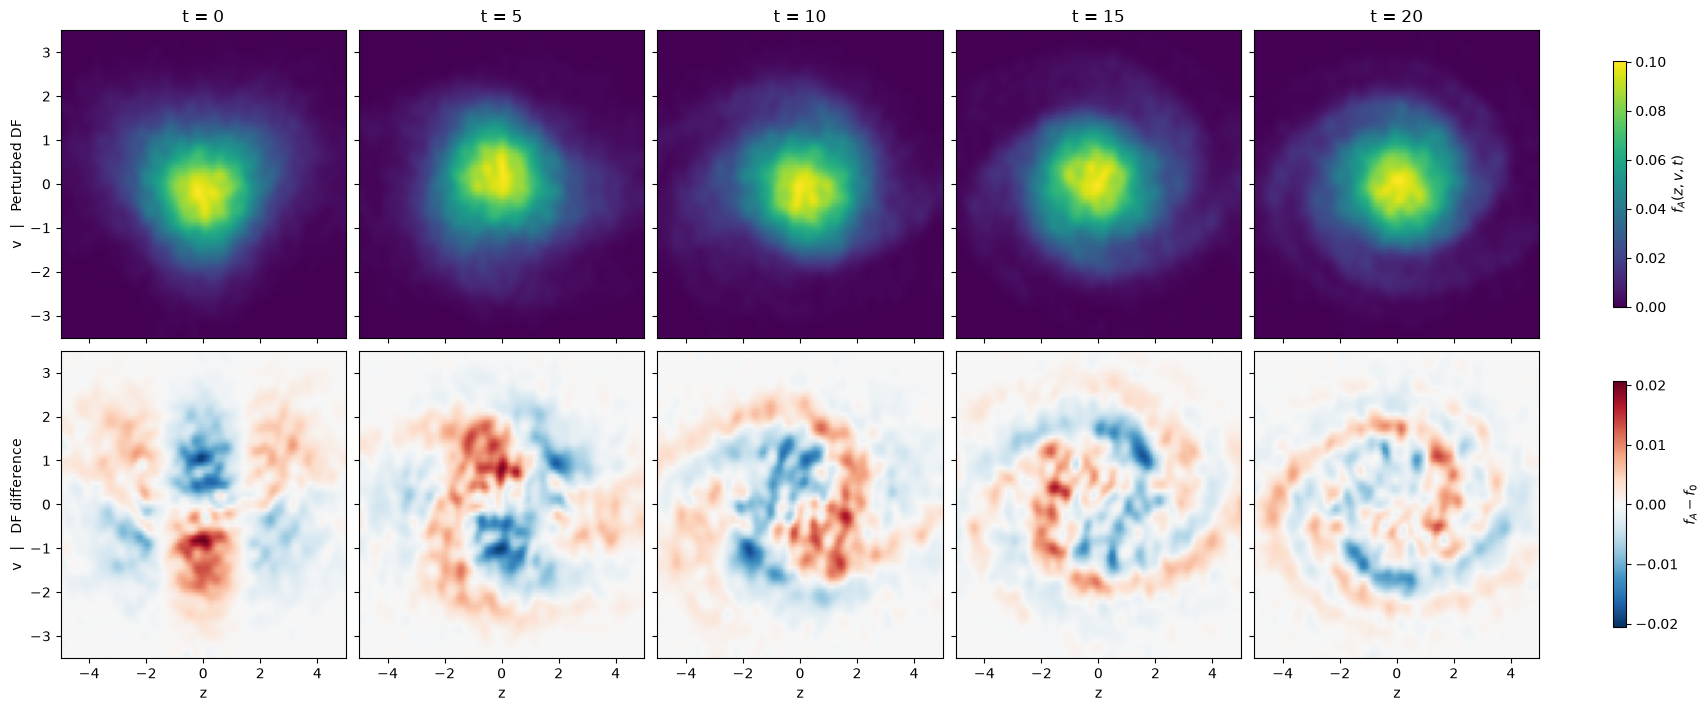

Unperturbed...
First kick only...


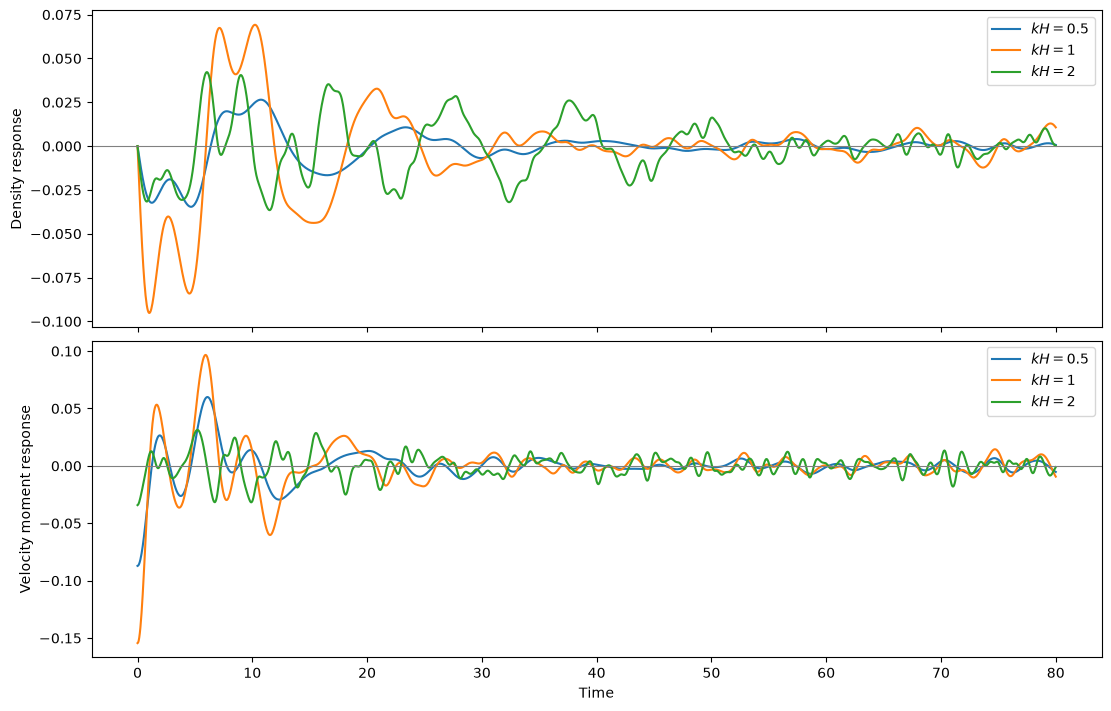

In [8]:

# Single-kick macroscopic phase-mixing diagnostic
tmax_test = 80.0
nt_test = round(tmax_test / dt)
test_times = np.arange(nt_test + 1) * dt

ks = np.array([0.5, 1.0, 2.0]) / H

def run_modes(v_initial):
    z = z0.copy()
    v = v_initial.copy()

    sim = wendy.nbody(
        z, v, m, dt,
        approx=True, nleap=nleap
    )

    D = np.zeros((nt_test + 1, len(ks)))
    P = np.zeros_like(D)

    for i in range(nt_test + 1):
        zc = z - z.mean()
        vc = v - v.mean()

        phase = zc[:, None] * ks[None, :]

        D[i] = np.mean(np.sin(phase), axis=0)
        P[i] = np.mean(
            vc[:, None] * np.cos(phase), axis=0
        )

        if i < nt_test:
            z, v = next(sim)

    return D, P

print("Unperturbed...")
D0, P0 = run_modes(v0)

print("First kick only...")
DA, PA = run_modes(v0 + dv_A)

dD = DA - D0
dP = PA - P0

fig, axes = plt.subplots(
    2, 1, figsize=(11, 7),
    sharex=True, layout="constrained"
)

for j, k in enumerate(ks):
    axes[0].plot(
        test_times, dD[:, j],
        label=fr"$kH={k*H:g}$"
    )
    axes[1].plot(
        test_times, dP[:, j],
        label=fr"$kH={k*H:g}$"
    )

axes[0].set_ylabel("Density response")
axes[1].set_ylabel("Velocity moment response")
axes[1].set_xlabel("Time")

for ax in axes:
    ax.axhline(0, color="gray", lw=0.8)
    ax.legend()

plt.show()
